# Model Evaluation

## Objective

In this phase, we evaluate the performance of all trained machine learning models on unseen test data.

The evaluation includes:

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix
- Classification Report

Finally, all models are compared to determine the best-performing classifier for Fake Job Posting Detection.

### Import Libraries

In [2]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import sparse

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

### load Test Data

In [3]:
X_test = sparse.load_npz("../data/X_test.npz")

y_test = pd.read_csv("../data/y_test.csv").squeeze()

### Load Models

In [4]:
logistic_model = joblib.load("../models/logistic_regression.pkl")

naive_bayes_model = joblib.load("../models/naive_bayes.pkl")

random_forest_model = joblib.load("../models/random_forest.pkl")

### Generate Predictions

In [5]:
y_pred_lr = logistic_model.predict(X_test)

y_pred_nb = naive_bayes_model.predict(X_test)

y_pred_rf = random_forest_model.predict(X_test)

### Evaluate Logistic Regression

In [6]:
print("="*60)
print("Logistic Regression Performance")
print("="*60)

print(f"Accuracy  : {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_lr):.4f}")

print("\nClassification Report\n")

print(classification_report(y_test, y_pred_lr))

Logistic Regression Performance
Accuracy  : 0.9723
Precision : 1.0000
Recall    : 0.4277
F1 Score  : 0.5992

Classification Report

              precision    recall  f1-score   support

           0       0.97      1.00      0.99      3403
           1       1.00      0.43      0.60       173

    accuracy                           0.97      3576
   macro avg       0.99      0.71      0.79      3576
weighted avg       0.97      0.97      0.97      3576



### Confusion Matrix (Logistic Regression)

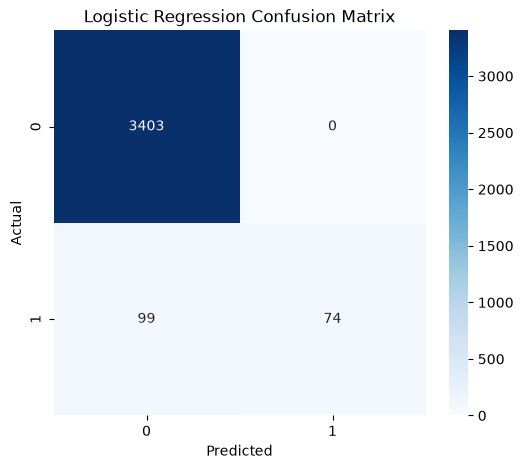

In [7]:
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

### Evaluate Naive Bayes

In [8]:
print("="*60)
print("Multinomial Naive Bayes Performance")
print("="*60)

print(f"Accuracy  : {accuracy_score(y_test, y_pred_nb):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_nb):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_nb):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_nb):.4f}")

print("\nClassification Report\n")

print(classification_report(y_test, y_pred_nb))

Multinomial Naive Bayes Performance
Accuracy  : 0.9676
Precision : 0.9831
Recall    : 0.3353
F1 Score  : 0.5000

Classification Report

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3403
           1       0.98      0.34      0.50       173

    accuracy                           0.97      3576
   macro avg       0.98      0.67      0.74      3576
weighted avg       0.97      0.97      0.96      3576



### Confusion Matrix (Naive Bayes)

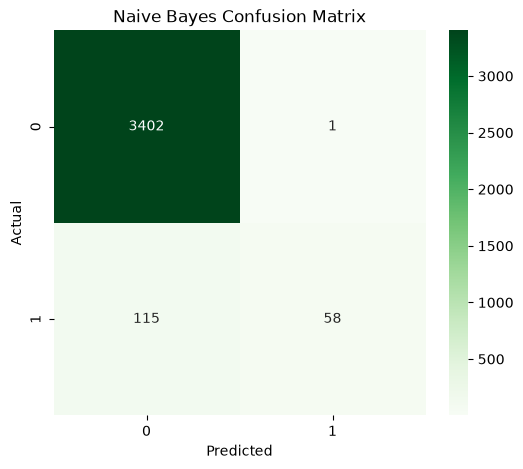

In [9]:
cm = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Naive Bayes Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

### Evaluate Random Forest

In [10]:
print("="*60)
print("Random Forest Performance")
print("="*60)

print(f"Accuracy  : {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_rf):.4f}")

print("\nClassification Report\n")

print(classification_report(y_test, y_pred_rf))

Random Forest Performance
Accuracy  : 0.9813
Precision : 1.0000
Recall    : 0.6127
F1 Score  : 0.7599

Classification Report

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3403
           1       1.00      0.61      0.76       173

    accuracy                           0.98      3576
   macro avg       0.99      0.81      0.88      3576
weighted avg       0.98      0.98      0.98      3576



### Confusion Matrix (Random Forest)

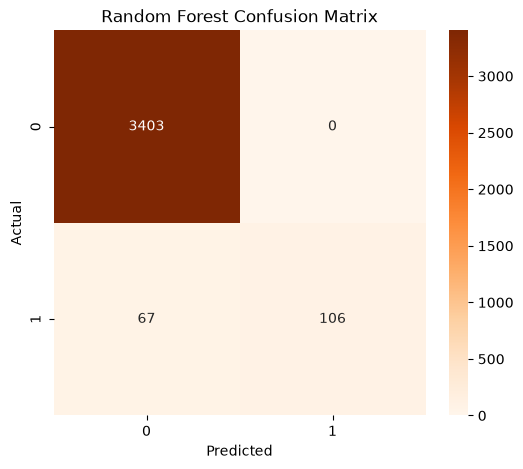

In [11]:
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

### Create Comparision Table

In [12]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_rf)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.972315,1.000000,0.427746,0.599190
1,Naive Bayes,0.967562,0.983051,0.335260,0.500000
2,Random Forest,0.981264,1.000000,0.612717,0.759857


### Sort By Accuracy

In [13]:
comparison.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.981264,1.000000,0.612717,0.759857
0,Logistic Regression,0.972315,1.000000,0.427746,0.599190
1,Naive Bayes,0.967562,0.983051,0.335260,0.500000


### Bar Chart Comparision

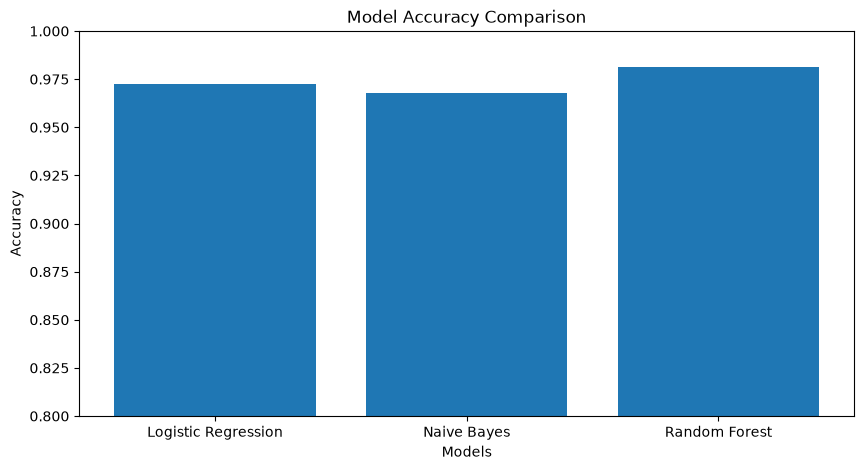

In [14]:
plt.figure(figsize=(10,5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy"]
)

plt.title("Model Accuracy Comparison")

plt.xlabel("Models")

plt.ylabel("Accuracy")

plt.ylim(0.8,1.0)

plt.show()